# 09 · ¿El score discrimina? ¿TPV aporta algo que el buró no ve? ¿Qué pasa con los rechazados?

**Preguntas de decisión**

1. **¿El score de buró sigue ordenando el riesgo, en cada estrategia y en cada cosecha?** Un score que pierde poder o cuya población cambió deja la política funcionando a ciegas.
2. **¿El TPV del comercio aporta información incremental sobre el buró?** Es la pregunta que justifica, o no, una estrategia de originación con datos alternativos.
3. **¿Qué ganamos o perdemos con una política alternativa?** Las solicitudes que la alternativa aprobaría y la actual no (*swap-in*) no tienen desempeño interno. Sin estimarlo, cualquier propuesta de aflojar el corte o ampliar TPV es una apuesta.

**Impacto esperado:** una decisión de crecimiento con base cuantitativa: ampliar, restringir o reenfocar TPV, y cuánto riesgo traen las solicitudes nuevas.

> **Estado:** plantilla con demostración aislada simulada. El oráculo de la simulación conoce el desempeño de los rechazados; se usa **solo** para comprobar el método.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
BASE = Path.cwd()
if not (BASE / 'decision_core.py').exists():
    root = next(p for p in [BASE, *BASE.parents] if (p / '03-financial-risk').is_dir())
    BASE = root / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
sys.path.insert(0, str(BASE))
import decision_core as dc
from vintage_core import build_vintage, summarize_vintage
from demo_inputs import demo_cartera
plt.rcParams.update({'figure.figsize': (10, 4.6), 'font.size': 10.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
AZUL, OCRE, GRIS, ROJO = '#25658c', '#d4854a', '#9aa5b1', '#b5443b'
SIM = 'Datos simulados · no representa una cartera'
pd.options.display.float_format = '{:,.4f}'.format

def leer(nombre):
    """Lee una plantilla local; las del repositorio solo tienen encabezados."""
    return pd.read_csv(BASE / nombre, encoding='utf-8-sig')

def pct(x, d=1):
    return 'n/d' if pd.isna(x) else f'{100 * x:.{d}f} %'

def cop(x):
    return 'n/d' if pd.isna(x) else f'COP {x / 1e6:,.1f} M'

## 1 · Discriminación, orden y estabilidad del score

- **AUC** $=\Pr(s_{\text{bueno}}>s_{\text{malo}})$; **Gini** $=2\,\text{AUC}-1$; **KS** $=\max_s |F_{\text{malo}}(s)-F_{\text{bueno}}(s)|$.
- **Orden por bandas:** la tasa de malos debe caer de forma monótona con el score; una inversión indica una banda mal calibrada o una población distinta.
- **PSI** $=\sum_k (q_k-p_k)\ln(q_k/p_k)$ sobre bandas fijadas en la población base. Umbrales de práctica: $<0{,}10$ estable, $0{,}10$–$0{,}25$ vigilar, $>0{,}25$ cambio material. El PSI de **solicitudes** mide cambio de población; el de **aprobados** mezcla población y política.

Todo se calcula sobre aprobados con desempeño maduro: el Gini observado está **truncado** por el corte y subestima el poder del score en la población de solicitantes.

### Con datos de la entidad

In [2]:
solic = leer('plantilla_solicitudes.csv'); retro = leer('plantilla_bureau_retro.csv')
print(f'Solicitudes: {len(solic):,} | registros bureau retro: {len(retro):,}')
if solic.empty:
    print('PENDIENTE: todas las solicitudes (aprobadas y rechazadas) con score, versión de política y decisión.')
if retro.empty:
    print('PENDIENTE: desempeño en otras entidades (bureau retro) con acuerdo del proveedor, base legal y definición de malo alineada.')

Solicitudes: 0 | registros bureau retro: 0
PENDIENTE: todas las solicitudes (aprobadas y rechazadas) con score, versión de política y decisión.
PENDIENTE: desempeño en otras entidades (bureau retro) con acuerdo del proveedor, base legal y definición de malo alineada.


### Demostración aislada

In [3]:
# Cartera ficticia con mecanismos plantados (ver demo_inputs.demo_cartera).
DEMO = demo_cartera()
V = DEMO['verdad']
cuentas, solicitudes, panel_demo, macro_demo = DEMO['cuentas'], DEMO['solicitudes'], DEMO['panel'], DEMO['macro']
cuentas['banda_score'] = pd.cut(cuentas.score_buro, [0, 620, 660, 700, 2000], right=False,
                                labels=['<620', '620–659', '660–699', '700+'])
print(f'Solicitudes simuladas: {len(solicitudes):,} | aprobadas: {len(cuentas):,} | '
      f'EVER30@MOB3 simulado: {pct(cuentas.evento_temprano.mean())}')

Solicitudes simuladas: 30,000 | aprobadas: 20,379 | EVER30@MOB3 simulado: 10.5 %


,estrategia,n,malos,auc,gini,ks
0,Experian,14064,1575,0.6209,0.2419,0.1902
1,TPV,6315,568,0.5730,0.1461,0.1326


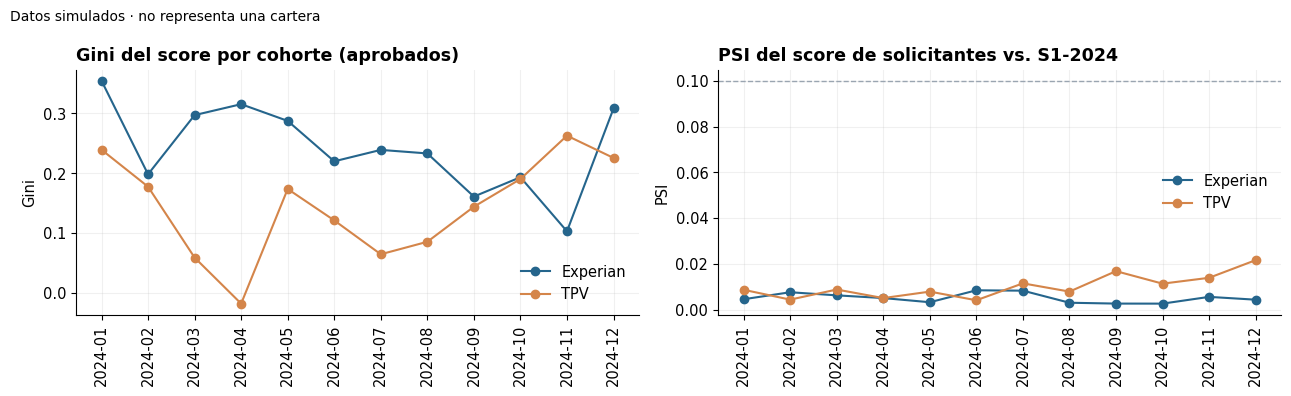

In [4]:
filas = []
for (est, coh), g in cuentas.groupby(['estrategia_originacion', 'corte_origen']):
    filas.append({'estrategia': est, 'cohorte': coh} | dc.discrimination(g.score_buro, g.evento_temprano))
gini = pd.DataFrame(filas)
global_ = pd.DataFrame([{'estrategia': est} | dc.discrimination(g.score_buro, g.evento_temprano)
                        for est, g in cuentas.groupby('estrategia_originacion')])
display(global_)

base_sol = solicitudes[solicitudes.corte_origen < '2024-07']
psi = pd.DataFrame([{'estrategia': est, 'cohorte': coh,
                     'psi_solicitudes': dc.psi(base_sol.loc[base_sol.estrategia_originacion == est, 'score_buro'], g.score_buro)}
                    for (est, coh), g in solicitudes.groupby(['estrategia_originacion', 'corte_origen'])])

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for est, color in [('Experian', AZUL), ('TPV', OCRE)]:
    g = gini[gini.estrategia == est]; p = psi[psi.estrategia == est]
    axs[0].plot(g.cohorte, g.gini, marker='o', color=color, label=est)
    axs[1].plot(p.cohorte, p.psi_solicitudes, marker='o', color=color, label=est)
axs[0].set(title='Gini del score por cohorte (aprobados)', ylabel='Gini'); axs[1].axhline(.10, color=GRIS, ls='--', lw=1)
axs[1].set(title='PSI del score de solicitantes vs. S1-2024', ylabel='PSI')
for ax in axs: ax.tick_params(axis='x', rotation=90); ax.legend(frameon=False)
fig.suptitle(SIM, x=.01, ha='left', fontsize=10); plt.tight_layout(); plt.show()
ge = global_.set_index('estrategia')
assert ge.loc['Experian', 'gini'] > ge.loc['TPV', 'gini'], 'En la simulación el score es menos informativo en TPV'
assert psi.psi_solicitudes.max() < .10, 'La simulación no planta cambios de población del score'

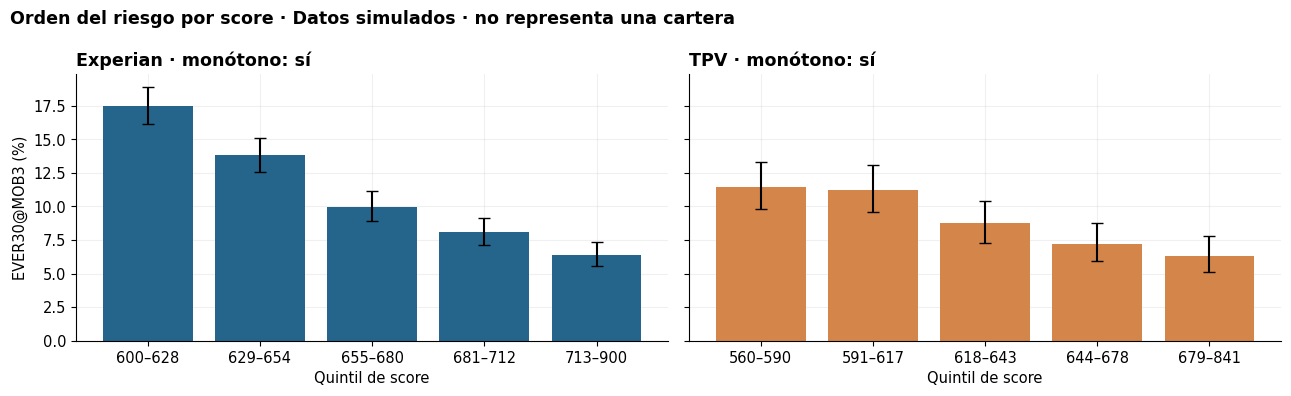

**Lectura (simulada).** El score ordena en ambas estrategias, pero su Gini en TPV (0.15) es menor que en Experian (0.24): en clientes con poca historia el buró ve menos. El PSI se mantiene bajo 0,10 (máximo 0.022), así que no hay cambio de población que explique las diferencias entre cohortes.

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
orden = {}
for ax, (est, color) in zip(axs, [('Experian', AZUL), ('TPV', OCRE)]):
    g = cuentas[cuentas.estrategia_originacion == est]
    r = dc.rank_order(g.score_buro, g.evento_temprano, n_bins=5); orden[est] = r
    x = np.arange(len(r))
    ax.bar(x, 100 * r.tasa_malos, color=color, yerr=[100 * (r.tasa_malos - r.ic_bajo), 100 * (r.ic_alto - r.tasa_malos)], capsize=4)
    ax.set_xticks(x, [f'{a:.0f}–{b:.0f}' for a, b in zip(r.score_min, r.score_max)])
    ax.set(title=f"{est} · monótono: {'sí' if r.attrs['monotono'] else 'no'}", xlabel='Quintil de score')
axs[0].set_ylabel('EVER30@MOB3 (%)'); fig.suptitle(f'Orden del riesgo por score · {SIM}', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); plt.show()
display(Markdown(f"**Lectura (simulada).** El score ordena en ambas estrategias, pero su Gini en TPV ({ge.loc['TPV', 'gini']:.2f}) es menor "
                 f"que en Experian ({ge.loc['Experian', 'gini']:.2f}): en clientes con poca historia el buró ve menos. El PSI se mantiene "
                 f"bajo 0,10 (máximo {psi.psi_solicitudes.max():.3f}), así que no hay cambio de población que explique las diferencias "
                 "entre cohortes."))

## 2 · Valor incremental del TPV

Dentro de TPV se comparan dos modelos logísticos fuera de tiempo (entrenamiento con cohortes hasta 2024-06, evaluación con las posteriores): solo score frente a score + $\log$ TPV. La métrica es el **ΔAUC** con IC bootstrap pareado. Si el TPV aporta, la estrategia tiene fundamento y la siguiente pregunta es dónde ponderarlo (notebook 08: ¿en qué bandas cambia el valor?).

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

tpv = cuentas[cuentas.estrategia_originacion == 'TPV'].assign(log_tpv=lambda d: np.log(d.tpv_mensual_cop))
train, test = tpv[tpv.corte_origen <= '2024-06'], tpv[tpv.corte_origen > '2024-06']
pred = {}
for nombre, X in [('solo score', ['score_buro']), ('score + TPV', ['score_buro', 'log_tpv'])]:
    m = make_pipeline(StandardScaler(), LogisticRegression()).fit(train[X], train.evento_temprano)
    pred[nombre] = m.predict_proba(test[X])[:, 1]
y = test.evento_temprano.to_numpy()
auc = {k: dc.discrimination(-v, y)['auc'] for k, v in pred.items()}
rng = np.random.default_rng(11); deltas = []
for _ in range(400):
    i = rng.integers(0, len(y), len(y))
    deltas.append(dc.discrimination(-pred['score + TPV'][i], y[i])['auc'] - dc.discrimination(-pred['solo score'][i], y[i])['auc'])
lo, hi = np.quantile(deltas, [.025, .975])
print(f"Evaluación fuera de tiempo: {len(test):,} cuentas TPV | AUC solo score {auc['solo score']:.3f} | "
      f"score + TPV {auc['score + TPV']:.3f} | ΔAUC {auc['score + TPV'] - auc['solo score']:+.3f} (IC 95 % {lo:+.3f} a {hi:+.3f})")

tpv['banda'] = pd.qcut(tpv.score_buro, 3, labels=['score bajo', 'score medio', 'score alto'])
tpv['tercil_tpv'] = tpv.groupby('banda', observed=True).log_tpv.transform(lambda s: pd.qcut(s, 3, labels=['TPV bajo', 'TPV medio', 'TPV alto']))
cruce = tpv.pivot_table(index='banda', columns='tercil_tpv', values='evento_temprano', aggfunc='mean', observed=True)
display(cruce.style.format('{:.1%}'))
delta = auc['score + TPV'] - auc['solo score']
assert delta > 0, 'En la simulación el TPV contiene información sobre el riesgo latente'
concl = ('con IC por encima de cero: el aporte está demostrado fuera de tiempo' if lo > 0 else
         'pero el IC todavía incluye cero: con este volumen de evaluación el aporte no está demostrado y conviene ampliar la ventana')
display(Markdown(f"**Lectura (simulada).** El TPV agrega {100 * delta:.1f} puntos de AUC fuera de tiempo, {concl}. Dentro de cada banda "
                 "de score la mora cae al subir el TPV, lo que indica información que el buró no captura. Si se confirma, el uso natural "
                 "es aprobar solicitudes que el buró solo rechaza (sección 3)."))

Evaluación fuera de tiempo: 3,181 cuentas TPV | AUC solo score 0.583 | score + TPV 0.612 | ΔAUC +0.029 (IC 95 % -0.004 a +0.066)


tercil_tpv,TPV bajo,TPV medio,TPV alto
banda,,,
score bajo,13.2%,12.8%,7.3%
score medio,11.9%,9.7%,5.9%
score alto,9.6%,6.7%,3.7%


**Lectura (simulada).** El TPV agrega 2.9 puntos de AUC fuera de tiempo, pero el IC todavía incluye cero: con este volumen de evaluación el aporte no está demostrado y conviene ampliar la ventana. Dentro de cada banda de score la mora cae al subir el TPV, lo que indica información que el buró no captura. Si se confirma, el uso natural es aprobar solicitudes que el buró solo rechaza (sección 3).

## 3 · Swap set e inferencia de rechazados

Se compara la política vigente (A) con una alternativa (B). Las cuatro celdas son: ambas aprueban; **swap-out** (A aprueba, B rechaza: desempeño observado); **swap-in** (B aprueba, A rechaza: sin desempeño interno); ambas rechazan.

**Método principal: modelo en aprobados.** Si la aprobación depende solo de variables observadas (una regla de score y TPV), la selección es ignorable condicional a ellas: un modelo $\Pr(\text{malo}\mid x)$ ajustado en aprobados es válido para los rechazados **dentro del soporte** de los aprobados. Fuera de ese soporte (scores o TPV que nunca se aprobaron) la predicción es extrapolación, y se reporta como tal. Con *overrides* manuales la selección depende también de información no observada y el supuesto falla.

**Contraste: bureau retro por bandas.** $\kappa_k=\text{tasa interna}_k/\text{tasa retro}_k$ entre aprobados de la banda $, aplicado a la tasa retro de sus rechazados. Es simple, pero se sesga cuando los rechazados de una banda son más riesgosos que sus aprobados, y no existe donde la banda no tuvo aprobados. El retro es más valioso para **validar** la extrapolación y para detectar selección por no observables.

**Evidencia definitiva:** aprobar una muestra controlada del swap-in (notebook 11).

In [7]:
s = solicitudes.copy()
s['log_tpv'] = np.log(s.tpv_mensual_cop)
# Alternativa B (ilustrativa): Experian exige 620; TPV baja a 540 si el TPV es alto.
s['politica_b'] = np.where(s.estrategia_originacion == 'TPV', (s.score_buro >= 540) & (s.log_tpv >= 14.6), s.score_buro >= 620).astype(int)
s['banda'] = pd.cut(s.score_buro, [0, 540, 560, 580, 600, 620, 660, 700, 2000], right=False).astype(str)
s['banda_estrategia'] = s.estrategia_originacion + ' ' + s.banda
swap = dc.swap_matrix(s, decision_a='aprobada', decision_b='politica_b', bad_col='evento_interno_mob3')
display(swap)

oraculo = V['oraculo_evento_por_solicitud']
VARIABLES = {'Experian': ['score_buro'], 'TPV': ['score_buro', 'log_tpv']}
s['malo_inferido'] = np.nan; s['distancia_sd'] = np.nan; diagnosticos = []
for est, X in VARIABLES.items():
    g = s[s.estrategia_originacion == est]
    rech = g[g.aprobada == 0]
    pred, diag = dc.infer_rejects_model(g[g.aprobada == 1], rech, features=X, outcome_col='evento_interno_mob3')
    s.loc[pred.index, 'malo_inferido'] = pred; s.loc[pred.index, 'distancia_sd'] = pred.attrs['distancia_sd']
    diagnosticos.append(diag.assign(estrategia=est))
display(pd.concat(diagnosticos)[['estrategia', 'min_aprobados', 'max_aprobados', 'fraccion_fuera_soporte', 'distancia_max_sd']])

swap_in = s[(s.aprobada == 0) & (s.politica_b == 1)].copy()
swap_in['oraculo'] = oraculo.reindex(swap_in.id_solicitud).to_numpy()
todos_rech = s[s.aprobada == 0].assign(oraculo=lambda d: oraculo.reindex(d.id_solicitud).to_numpy())

inf = dc.infer_rejects_retro(s, band_col='banda_estrategia', approved_col='aprobada', internal_bad_col='evento_interno_mob3',
                             retro_bad_col='retro_malo_12m')
retro_in = swap_in.merge(inf[['banda_estrategia', 'factor_k']], on='banda_estrategia', how='left')
retro_in = (retro_in.factor_k * retro_in.retro_malo_12m)

comparacion = pd.DataFrame({
    'n': [len(swap_in), len(swap_in), len(todos_rech)],
    'cobertura': [swap_in.malo_inferido.notna().mean(), retro_in.notna().mean(), todos_rech.malo_inferido.notna().mean()],
    'distancia_mediana_sd': [swap_in.distancia_sd.median(), np.nan, todos_rech.distancia_sd.median()],
    'tasa_inferida': [swap_in.malo_inferido.mean(), retro_in.mean(), todos_rech.malo_inferido.mean()],
    'oraculo': [swap_in.oraculo.mean(), swap_in.oraculo[retro_in.notna().to_numpy()].mean(), todos_rech.oraculo.mean()]},
    index=['swap-in · modelo en aprobados', 'swap-in · bureau retro por bandas', 'todos los rechazados · modelo'])
comparacion['error_pp'] = 100 * (comparacion.tasa_inferida - comparacion.oraculo)
display(comparacion)
assert abs(comparacion.loc['swap-in · modelo en aprobados', 'error_pp']) < 2, 'El modelo en aprobados no recupera el swap-in'

,aprobada,politica_b,n,n_con_desempeno,tasa_malos_observada,celda
0,0,0,7744,0,NaN,ambas rechazan
1,0,1,1877,0,NaN,swap-in: solo politica_b aprueba
2,1,0,1914,1914,0.1970,swap-out: solo aprobada aprueba
3,1,1,18465,18465,0.0956,ambas aprueban


,estrategia,min_aprobados,max_aprobados,fraccion_fuera_soporte,distancia_max_sd
score_buro,Experian,600.0000,900.0000,1.0000,3.9327
score_buro,TPV,560.0000,841.0000,0.5741,4.4410
log_tpv,TPV,14.8002,16.8833,0.7235,4.7322


,n,cobertura,distancia_mediana_sd,tasa_inferida,oraculo,error_pp
swap-in · modelo en aprobados,1877,1.0000,0.2411,0.1503,0.1550,-0.4693
swap-in · bureau retro por bandas,1877,0.5157,NaN,0.2117,0.1767,3.5050
todos los rechazados · modelo,9621,1.0000,0.7341,0.2250,0.2451,-2.0072


,política vigente (A),alternativa (B)
aprobaciones,"20,379.0000","20,342.0000"
EVER30@MOB3 esperado,0.1052,0.1007


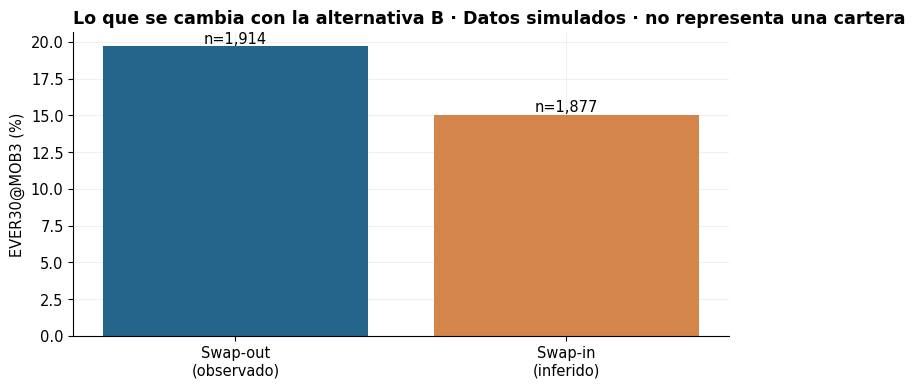

**Lectura (simulada).** La alternativa B cambia 1,914 aprobaciones (swap-out, 19.7 % de malos observados) por 1,877 (swap-in, 15.0 % inferidos). El EVER esperado pasa de 10.5 % a 10.1 % con -37 aprobaciones netas: B **reasigna** aprobación de Experian de score bajo hacia TPV con TPV alto, con menos riesgo por cuenta. Con una regla determinística todo rechazado está fuera del soporte en alguna variable; lo que cambia es la distancia (mediana 0.24 DE en el swap-in frente a 0.73 en todos los rechazados). El modelo en aprobados acierta en el swap-in (error -0.5 pp), cercano al soporte; para todos los rechazados, que exigen extrapolar más lejos, el error es -2.0 pp. El método retro por bandas se equivoca en +3.5 pp. Por eso cualquier aflojamiento lejos del corte requiere una muestra controlada.

In [8]:
tasa_in = comparacion.loc['swap-in · modelo en aprobados', 'tasa_inferida']
fila_out = swap[swap.celda.str.startswith('swap-out')].iloc[0]
tasa_out, n_out, n_in = fila_out.tasa_malos_observada, int(fila_out.n), len(swap_in)
aprob_a, aprob_b = int(s.aprobada.sum()), int(s.politica_b.sum())
malos_a = s.loc[s.aprobada == 1, 'evento_interno_mob3'].sum()
ambas = s[(s.aprobada == 1) & (s.politica_b == 1)]
malos_b = ambas.evento_interno_mob3.sum() + swap_in.malo_inferido.sum()
display(pd.DataFrame({'política vigente (A)': [aprob_a, malos_a / aprob_a], 'alternativa (B)': [aprob_b, malos_b / aprob_b]},
                     index=['aprobaciones', 'EVER30@MOB3 esperado']))
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(['Swap-out\n(observado)', 'Swap-in\n(inferido)'], [100 * tasa_out, 100 * tasa_in], color=[AZUL, OCRE])
ax.bar_label(ax.containers[0], labels=[f'n={n_out:,}', f'n={n_in:,}'])
ax.set(ylabel='EVER30@MOB3 (%)', title=f'Lo que se cambia con la alternativa B · {SIM}'); plt.tight_layout(); plt.show()
sesgo_lejos = comparacion.loc['todos los rechazados · modelo', 'error_pp']
display(Markdown(f"**Lectura (simulada).** La alternativa B cambia {n_out:,} aprobaciones (swap-out, {pct(tasa_out)} de malos observados) "
                 f"por {n_in:,} (swap-in, {pct(tasa_in)} inferidos). El EVER esperado pasa de {pct(malos_a / aprob_a)} a {pct(malos_b / aprob_b)} "
                 f"con {aprob_b - aprob_a:+,} aprobaciones netas: B **reasigna** aprobación de Experian de score bajo hacia TPV con TPV alto"
                 + (", con menos riesgo por cuenta. " if tasa_in < tasa_out else ", con más riesgo por cuenta. ") +
                 f"Con una regla determinística todo rechazado está fuera del soporte en alguna variable; lo que cambia es la distancia "
                 f"(mediana {comparacion.iloc[0].distancia_mediana_sd:.2f} DE en el swap-in frente a {comparacion.iloc[2].distancia_mediana_sd:.2f} en todos los rechazados). El modelo en aprobados acierta en el swap-in (error {comparacion.loc['swap-in · modelo en aprobados', 'error_pp']:+.1f} pp), "
                 f"cercano al soporte; para todos los rechazados, que exigen extrapolar más lejos, el error es {sesgo_lejos:+.1f} pp. El método retro "
                 f"por bandas se equivoca en {comparacion.loc['swap-in · bureau retro por bandas', 'error_pp']:+.1f} pp. Por eso cualquier "
                 "aflojamiento lejos del corte requiere una muestra controlada."))

## Decisiones y límites

- **Score:** vigilar Gini, orden y PSI por estrategia y cohorte en el tablero mensual; un Gini que cae con PSI estable indica que el score perdió poder, no que cambió la población.
- **TPV:** la información incremental se demuestra fuera de tiempo, no dentro de la muestra. Si se confirma, conviene evaluar un **score propio** que combine buró y TPV, en vez de usar el TPV solo como filtro.
- **Rechazados:** el bureau retro requiere acuerdo con el proveedor, base legal y una definición de malo comparable. El factor $\kappa$ se apoya en los aprobados de la misma banda: es más débil donde hay pocos. La evidencia definitiva viene de aprobar una muestra controlada bajo el corte (notebook 11).
- **Sesgo de selección:** todo Gini y toda tasa observada describen aprobados; no se extrapolan a la población de solicitantes sin inferencia de rechazados.